#Exploratory Code
###``````````````**Written by M.Hamza**````````````````````

The training data can be found at "https://github.com/rpglab/Battery-Degradation-Neural-Network-Codes-Datasets"

# Log-Linear Hybrid NN vs. Vanilla NN for Battery Degradation Prediction

### A multi-stress log-linear  model

$$BD = \exp\big(b_0 + b_1\,T + b_2\,C + b_3\,SOC + b_4\,DOD + b_5\,SOH\big)$$

$$Ln(BD) = b_0 + b_1\,T + b_2\,C + b_3\,SOC + b_4\,DOD + b_5\,SOH$$



- **No physical-unit or sign requirement on any input.** Every feature enters linearly inside the `exp(...)`, so  is exactly as valid on raw physical units as it is on z-scored features — nothing needs to be un-normalized first. However, coefficients will loose physical interpretability.
- **Guarantees non-negative degradation**, `exp(anything) > 0`.


**Architecture used here:**
`prediction = exp(LogLinear(T, C, SOC, DOD, SOH; b0..b5)) * exp(NN_residual)`

- The **Loglinear branch** has only 6 learnable parameters . It's a log-linear regression, so 0.01% of the data constrains it well.
- The **residual branch** is a small NN that picks up whatever the log-linear law misses


## Import libraries and set hyperparameters

In [ ]:
import os
import copy
import numpy as np
import torch
from torch import nn
import torch.utils.data as Data
from torch.optim import lr_scheduler
import matplotlib.pyplot as plt

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

torch.manual_seed(0)
torch.cuda.manual_seed_all(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


FEATURE_NAMES = ["T", "C", "SOC", "DOD", "SOH"]

BATCH_SIZE = 256
NUM_EPOCHS = 50
NUM_EPOCHS_VNN = 520
NUM_EPOCHS_HYB = 520
LEARNING_RATE = 0.0005
LEARNING_RATE_HYB=0.01
LEARNING_RATE_HYBRID=0.001
FRACTION_LOW = 0.0001
RNG_SEED = 0

Using device: cuda


##Build the 0.01% / 100% training pools



In [ ]:
from sklearn.model_selection import train_test_split

x_sample = np.load("/content/x_sample.npy")
y_sample = np.load("/content/y_sample.npy")
x_test = np.load("/content/x_test.npy")
y_test = np.load("/content/y_test.npy")

# Split x_sample, y_sample into training and validation sets for the 100% model
# x_train_main and y_train_main will be the 100% training data
# x_val and y_val will be the validation data for the 100% model
x_train_main, x_val, y_train_main, y_val = train_test_split(
    x_sample, y_sample, test_size=0.2, random_state=RNG_SEED
)

rng = np.random.default_rng(RNG_SEED)

# Create the 0.01% low-data training subset from x_train_main
n_total_main = x_train_main.shape[0]
n_low = max(int(np.ceil(FRACTION_LOW * n_total_main)), 32)
low_idx = rng.choice(n_total_main, size=n_low, replace=False)
x_low, y_low = x_train_main[low_idx], y_train_main[low_idx]

# Create a small validation set for the low-data models
n_small_val = max(int(np.ceil(FRACTION_LOW * x_val.shape[0] * 5)), 32) # Example: 5x the low data fraction of x_val
n_small_val = 200
small_val_idx = rng.choice(x_val.shape[0], size=n_small_val, replace=False)
x_small_val, y_small_val = x_val[small_val_idx], y_val[small_val_idx]


print(f"Full training pool (after train/val split): {x_train_main.shape[0]} samples")
print(f"Validation pool (for 100% model):          {x_val.shape[0]} samples")
print(f"0.01% labeled subset (from training pool): {x_low.shape[0]} samples")
print(f"Small validation pool (for low-data models): {x_small_val.shape[0]} samples")
print(f"Test pool (final evaluation):              {x_test.shape[0]} samples")

Full training pool (after train/val split): 2327814 samples
Validation pool (for 100% model):          581954 samples
0.01% labeled subset (from training pool): 233 samples
Small validation pool (for low-data models): 200 samples
Test pool (final evaluation):              721984 samples


## Set Vanilla NN Architecture

**5-20-10-1** Architecture


In [ ]:

class Net(nn.Module):
    """Same architecture as the original NNBD model: 5-20-10-1, ReLU hidden,
    linear output (Fig. 2 of the paper)."""
    def __init__(self, n_feature, n_hidden, n_output):
        super(Net, self).__init__()
        self.hidden = nn.Linear(n_feature, n_hidden)
        self.hidden1 = nn.Linear(n_hidden, 10)
        self.predict = nn.Linear(10, n_output)

    def forward(self, x):
        x = nn.functional.relu(self.hidden(x))
        x = nn.functional.relu(self.hidden1(x))
        x = self.predict(x)
        return x


def make_loader(x_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
    x_t = torch.Tensor(x_arr).to(device)
    y_t = torch.Tensor(y_arr).to(device)
    ds = Data.TensorDataset(x_t, y_t)
    return Data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def mape_bins(y_true, y_pred):
    """Accuracy-tolerance count """
    ape = np.abs((y_pred - y_true) / y_true) * 100
    n = len(y_true)
    c05 = np.sum((ape > 0) & (ape <= 5))
    c510 = np.sum((ape > 5) & (ape <= 10))
    c1015 = np.sum((ape > 10) & (ape <= 15))
    c1520 = np.sum((ape > 15) & (ape <= 20))
    return {
        "mape": float(np.mean(ape)),
        "acc_5": c05 / n,
        "acc_10": (c05 + c510) / n,
        "acc_15": (c05 + c510 + c1015) / n,
        "acc_20": (c05 + c510 + c1015 + c1520) / n,
    }


def train_vanilla_nn(x_train, y_train, x_val, y_val, x_test, y_test, num_epochs=NUM_EPOCHS,
                      lr=LEARNING_RATE, tag="model"):

    torch.manual_seed(RNG_SEED)
    torch.cuda.manual_seed_all(RNG_SEED)
    model = Net(x_train.shape[1], 20, 1).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    train_loader = make_loader(x_train, y_train, shuffle=True)
    x_val_t = torch.Tensor(x_val).to(device)
    y_val_t = torch.Tensor(y_val).to(device)
    x_test_t = torch.Tensor(x_test).to(device)

    history = {"train_loss": [], "val_loss": [], "test_loss": [], "mape": [],
               "acc_10": [], "acc_15": [], "acc_20": []}

    best_val_loss, best_epoch, best_state = float("inf"), -1, None

    for epoch in range(num_epochs):
        model.train()
        total_loss, n_batches = 0.0, 0
        for bx, by in train_loader:
            by = by.view(-1, 1)
            pred = model(bx)
            loss = criterion(pred, by)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1

        history["train_loss"].append(total_loss / n_batches)

        model.eval()
        with torch.no_grad():
            val_pred = model(x_val_t).cpu().numpy().flatten()
            val_loss = float(np.mean((val_pred - y_val) ** 2))
            history["val_loss"].append(val_loss)

            # Check for best validation loss and save model state
            if val_loss < best_val_loss:
                best_val_loss, best_epoch = val_loss, epoch
                best_state = copy.deepcopy(model.state_dict())

            y_pred = model(x_test_t).cpu().numpy().flatten()
            test_loss = float(np.mean((y_pred - y_test) ** 2))
            history["test_loss"].append(test_loss)
            metrics = mape_bins(y_test, y_pred)
            history["mape"].append(metrics["mape"])
            history["acc_10"].append(metrics["acc_10"])
            history["acc_15"].append(metrics["acc_15"])
            history["acc_20"].append(metrics["acc_20"])

        scheduler.step(val_loss)

        if (epoch + 1) % 100 == 0 or epoch == num_epochs - 1:
            print(f"[{tag}] epoch {epoch+1:3d}/{num_epochs}  "
                  f"train_loss={history['train_loss'][-1]:.6f}  "
                  f"val_loss={val_loss:.6f}  test_loss={test_loss:.6f}  MAPE={metrics['mape']:.2f}%  "
                  f"acc@10%={metrics['acc_10']:.3f}  "
                  )

    if best_state is not None:
        model.load_state_dict(best_state)
        history["best_epoch"] = best_epoch
        history["best_val_loss"] = best_val_loss

        with torch.no_grad():
            y_pred_final = model(x_test_t).cpu().numpy().flatten()
            history["final_test"] = mape_bins(y_test, y_pred_final)
            history["final_test"]["mse"] = float(np.mean((y_pred_final - y_test) ** 2))
            print(f"[{tag}] FINAL (best-val ckpt) test MAPE={history['final_test']['mape']:.2f}%  "
                  f"acc@10%={history['final_test']['acc_10']:.3f}")
    else:
        print(f"[{tag}] No best state saved, likely due to num_epochs=0 or no improvement.")

    return model, history

## Define Log-Linear and Hybrid NN


In [ ]:
def fit_physics_prior(x_low, y_low):
    y = np.clip(y_low.astype(np.float64), 1e-6, None)
    design = np.concatenate(
        [np.ones((x_low.shape[0], 1)), x_low.astype(np.float64)], axis=1
    )
    target = np.log(y)
    coeffs, *_ = np.linalg.lstsq(design, target, rcond=None)
    print("Physics warm start (log-linear coefficients):")
    for name, val in zip(["b0 (intercept)"] + FEATURE_NAMES, coeffs):
        print(f"    {name:<15s} {val: .4f}")
    return coeffs


class LogLinear(nn.Module):
    def __init__(self, n_feature, warm_start_beta=None):
        super().__init__()
        self.linear = nn.Linear(n_feature, 1)
        if warm_start_beta is not None:
            b0, *b_rest = warm_start_beta
            with torch.no_grad():
                self.linear.weight.copy_(torch.tensor(b_rest, dtype=torch.float32))
                self.linear.bias.copy_(torch.tensor([b0], dtype=torch.float32))

    def forward(self, x):
        return torch.exp(self.linear(x))  # to get back 'BD' from 'lnBD'


class Hybrid(nn.Module):
    """
    final_prediction = physics_prediction * exp(residual_NN(x))"""

    def __init__(self, n_feature, warm_start_beta=None, hidden=20):
        super().__init__()
        self.physics = LogLinear(n_feature, warm_start_beta=warm_start_beta)
        self.residual = nn.Sequential(
            nn.Linear(n_feature, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 10),
            nn.ReLU(),
            nn.Linear(10, 1),
        )
        nn.init.zeros_(self.residual[-1].weight)
        nn.init.zeros_(self.residual[-1].bias)

    def forward(self, x):
        phys = self.physics(x)
        res = self.residual(x)
        pred = phys * torch.exp(res)
        return pred, phys, res

## Implement Hybrid NN



In [ ]:

def val_mape(y_true, y_pred):
    return float(np.mean(np.abs((y_pred - y_true) / y_true)) * 100)

def predict_np(model, x_t, pure):
    with torch.no_grad():
        out = model(x_t)
        if not pure:
            out = out[0]
    return out.cpu().numpy().flatten()


def train_hybrid(x_low, y_low, x_val, y_val, x_test, y_test,
                 num_epochs=NUM_EPOCHS_HYB, lr=LEARNING_RATE_HYB,
                 w_phys_anchor=2, w_residual_reg=0.05,
                 tag="LogLinear-Hybrid-0.01%",
                 is_pure_loglinear=False,
                 patience=60,
                 track_test=True,
                 eval_test=True):

    torch.manual_seed(RNG_SEED)
    torch.cuda.manual_seed_all(RNG_SEED)
    warm_start_beta = fit_physics_prior(x_low, y_low)

    if is_pure_loglinear:
        model = LogLinear(x_low.shape[1], warm_start_beta=warm_start_beta).to(device)
    else:
        model = Hybrid(x_low.shape[1], warm_start_beta=warm_start_beta, hidden=20).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15)

    x_low_t = torch.Tensor(x_low).to(device)
    y_low_t = torch.Tensor(y_low).view(-1, 1).to(device)
    x_val_t = torch.Tensor(x_val).to(device)
    x_test_t = torch.Tensor(x_test).to(device) if (track_test or eval_test) else None

    history = {"train_loss": [], "val_loss": [], "val_mape": [], "test_loss": [],
               "mape": [], "acc_10": [], "acc_15": [], "acc_20": []}

    best_val, best_epoch, best_state = float("inf"), -1, None

    for epoch in range(num_epochs):
        model.train()
        if is_pure_loglinear:
            pred = model(x_low_t)
            loss = criterion(torch.log(torch.clamp(pred, min=1e-6)),
                             torch.log(torch.clamp(y_low_t, min=1e-6)))
        else:
            pred, phys, res = model(x_low_t)
            data_loss = torch.mean(((pred - y_low_t) / y_low_t) ** 2)
            phys_loss = torch.mean(((phys - y_low_t) / y_low_t) ** 2)
            res_reg = torch.mean(res ** 2)
            loss = data_loss + w_phys_anchor * phys_loss + w_residual_reg * res_reg

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history["train_loss"].append(loss.item())

        model.eval()
        val_pred = predict_np(model, x_val_t, is_pure_loglinear)
        v_mape = val_mape(y_val, val_pred)
        history["val_loss"].append(float(np.mean((val_pred - y_val) ** 2)))
        history["val_mape"].append(v_mape)
        scheduler.step(v_mape)

        if v_mape < best_val:
            best_val, best_epoch = v_mape, epoch
            best_state = copy.deepcopy(model.state_dict())

        if track_test:
            y_pred = predict_np(model, x_test_t, is_pure_loglinear)
            m = mape_bins(y_test, y_pred)
            history["test_loss"].append(float(np.mean((y_pred - y_test) ** 2)))
            history["mape"].append(m["mape"])
            history["acc_10"].append(m["acc_10"])
            history["acc_15"].append(m["acc_15"])
            history["acc_20"].append(m["acc_20"])

        if (epoch + 1) % 100 == 0 or epoch == num_epochs - 1:
            print(f"[{tag}] epoch {epoch+1:3d}/{num_epochs}  loss={loss.item():.6f}  "
                  f"val_MAPE={v_mape:.2f}%  best_val_MAPE={best_val:.2f}% (ep {best_epoch+1})")

        if patience and (epoch - best_epoch) >= patience:
            print(f"[{tag}] early stop at epoch {epoch+1}; best epoch {best_epoch+1}")
            break

    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    history["best_val_mape"] = best_val

    if eval_test:
        y_pred = predict_np(model, x_test_t, is_pure_loglinear)
        history["final_test"] = mape_bins(y_test, y_pred)
        history["final_test"]["mse"] = float(np.mean((y_pred - y_test) ** 2))
        print(f"[{tag}] FINAL (best-val ckpt) test MAPE={history['final_test']['mape']:.2f}%  "
              f"acc@10%={history['final_test']['acc_10']:.3f}")

    return model, history

##Train all four models

1. `Vanilla-NN-100%` — the original NNBD model with all labeled data (upper-bound baseline)
2. `Vanilla-NN-0.01%` — the same model with only 0.01% of the labeled data (weak baseline)
3. `LogLinear-0.01%` — the logLinear model with the same 0.01% labeled data
4. `LogLinear-0.01% * NN residual corrector`


In [ ]:

print("=" * 70)
print("Training Vanilla-NN on 100% of the data (upper-bound baseline)")
print("=" * 70)
model_100, hist_100 = train_vanilla_nn(
    x_train_main, y_train_main, x_val, y_val, x_test, y_test, num_epochs=NUM_EPOCHS, tag="Vanilla-NN-100%"
)

print("\n" + "=" * 70)
print("Training Vanilla-NN on a random 0.01% subset (data-starved baseline)")
print("=" * 70)
model_1pct, hist_1pct = train_vanilla_nn(
    x_low, y_low, x_small_val, y_small_val, x_test, y_test, num_epochs=NUM_EPOCHS_VNN, lr=LEARNING_RATE_HYB, tag="Vanilla-NN-0.01%"
)


print("\n" + "=" * 70)
print("Training a PURE Log-Linear model on the SAME 0.01% subset")
print("=" * 70)
model_pure_log, hist_pure_log = train_hybrid(
    x_low, y_low, x_small_val, y_small_val, x_test, y_test, num_epochs=NUM_EPOCHS_HYB, lr=LEARNING_RATE_HYB,
    tag="PureLogLinear-0.01%", is_pure_loglinear=True
)

print("\n" + "=" * 70)
print("Training the FULL Log-Linear + NN on the SAME 0.01% subset")
print("=" * 70)
model_hybrid_nn, hist_hybrid_nn = train_hybrid(
    x_low, y_low, x_small_val, y_small_val, x_test, y_test, num_epochs=NUM_EPOCHS_HYB, lr=LEARNING_RATE_HYBRID,
    w_phys_anchor=1.5, w_residual_reg=0.05, tag="Hybrid-NN-0.01%", is_pure_loglinear=False
)

Training Vanilla-NN on 100% of the data (upper-bound baseline)
[Vanilla-NN-100%] epoch  50/50  train_loss=0.000466  val_loss=0.000462  test_loss=0.000759  MAPE=3.97%  acc@10%=0.942  
[Vanilla-NN-100%] FINAL (best-val ckpt) test MAPE=3.97%  acc@10%=0.942

Training Vanilla-NN on a random 0.01% subset (data-starved baseline)
[Vanilla-NN-0.01%] epoch 100/520  train_loss=0.015360  val_loss=0.039972  test_loss=0.017816  MAPE=25.71%  acc@10%=0.368  
[Vanilla-NN-0.01%] epoch 200/520  train_loss=0.005415  val_loss=0.022831  test_loss=0.009612  MAPE=16.82%  acc@10%=0.418  
[Vanilla-NN-0.01%] epoch 300/520  train_loss=0.003074  val_loss=0.016441  test_loss=0.006198  MAPE=13.50%  acc@10%=0.588  
[Vanilla-NN-0.01%] epoch 400/520  train_loss=0.002507  val_loss=0.015511  test_loss=0.005398  MAPE=12.96%  acc@10%=0.615  
[Vanilla-NN-0.01%] epoch 500/520  train_loss=0.002507  val_loss=0.015511  test_loss=0.005398  MAPE=12.96%  acc@10%=0.615  
[Vanilla-NN-0.01%] epoch 520/520  train_loss=0.002507  val_lo

##Training curves


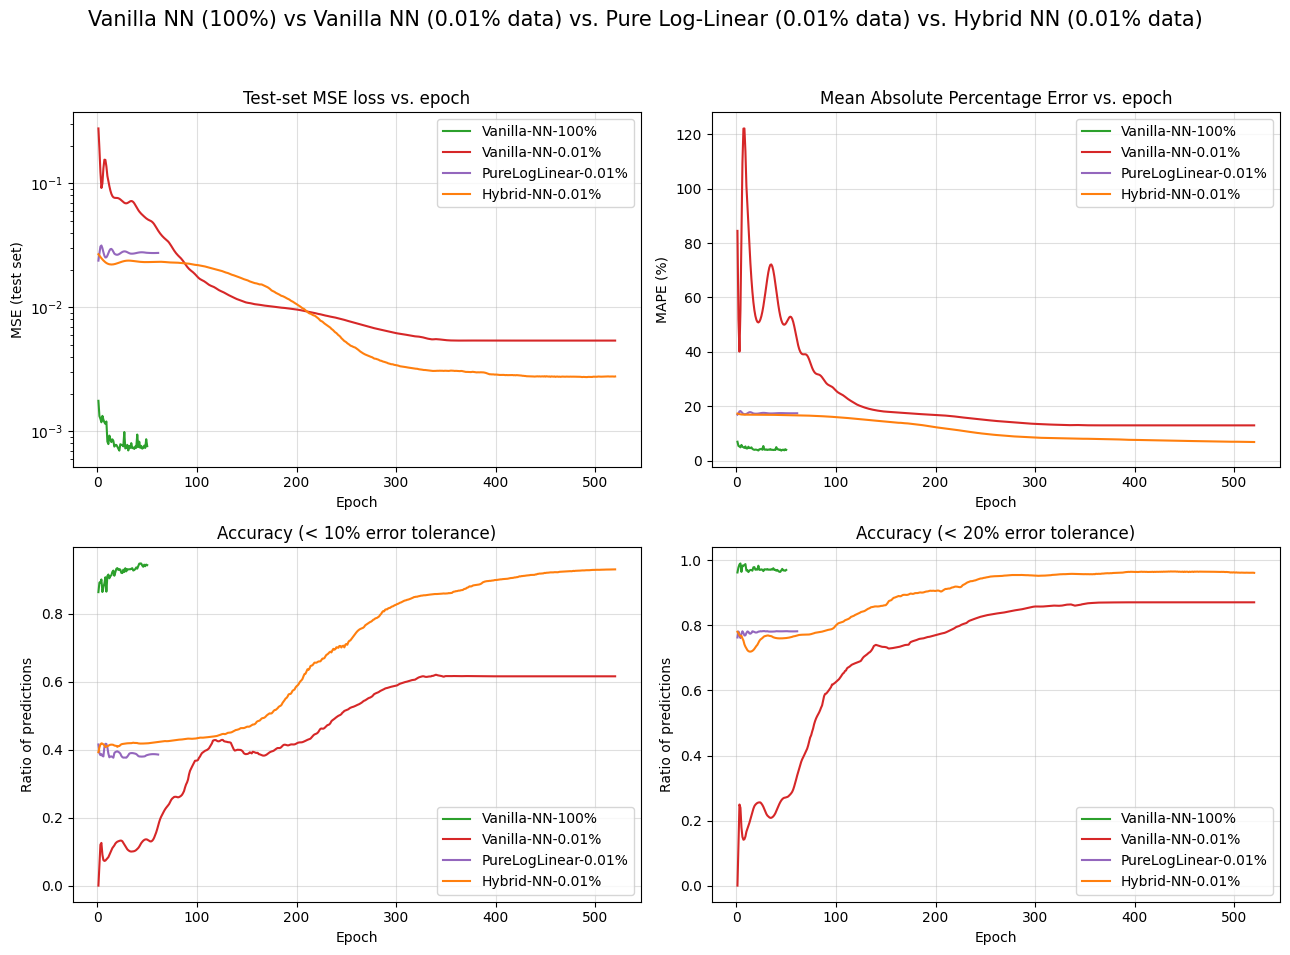

In [ ]:
runs = {
    "Vanilla-NN-100%": hist_100,
    "Vanilla-NN-0.01%": hist_1pct,
    "PureLogLinear-0.01%": hist_pure_log,
    "Hybrid-NN-0.01%": hist_hybrid_nn,
}
colors = {
    "Vanilla-NN-100%": "tab:green",
    "Vanilla-NN-0.01%": "tab:red",
    "PureLogLinear-0.01%": "tab:purple",
    "Hybrid-NN-0.01%": "tab:orange",
}

fig, axs = plt.subplots(2, 2, figsize=(13, 10))

for name, h in runs.items():
    epochs_range = np.arange(1, len(h["test_loss"]) + 1)
    axs[0, 0].plot(epochs_range, h["test_loss"], label=name, color=colors[name])
axs[0, 0].set_title("Test-set MSE loss vs. epoch")
axs[0, 0].set_xlabel("Epoch")
axs[0, 0].set_ylabel("MSE (test set)")
axs[0, 0].set_yscale("log")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.4)

for name, h in runs.items():
    epochs_range = np.arange(1, len(h["mape"]) + 1)
    axs[0, 1].plot(epochs_range, h["mape"], label=name, color=colors[name])
axs[0, 1].set_title("Mean Absolute Percentage Error vs. epoch")
axs[0, 1].set_xlabel("Epoch")
axs[0, 1].set_ylabel("MAPE (%)")
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.4)

for name, h in runs.items():
    epochs_range = np.arange(1, len(h["acc_10"]) + 1)
    axs[1, 0].plot(epochs_range, h["acc_10"], label=name, color=colors[name])
axs[1, 0].set_title("Accuracy (< 10% error tolerance)")
axs[1, 0].set_xlabel("Epoch")
axs[1, 0].set_ylabel("Ratio of predictions")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.4)

for name, h in runs.items():
    epochs_range = np.arange(1, len(h["acc_20"]) + 1)
    axs[1, 1].plot(epochs_range, h["acc_20"], label=name, color=colors[name])
axs[1, 1].set_title("Accuracy (< 20% error tolerance)")
axs[1, 1].set_xlabel("Epoch")
axs[1, 1].set_ylabel("Ratio of predictions")
axs[1, 1].legend()
axs[1, 1].grid(True, alpha=0.4)

fig.suptitle("Vanilla NN (100%) vs Vanilla NN (0.01% data) vs. Pure Log-Linear (0.01% data) vs. Hybrid NN (0.01% data)",
             fontsize=15)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


##Error and Accuracy plots


Model                     MAPE (%)     acc@10%     acc@15%     acc@20%
Vanilla-NN-100%               3.97       0.942       0.964       0.971
Vanilla-NN-0.01%             12.96       0.616       0.794       0.869
PureLogLinear-0.01%          16.91       0.415       0.580       0.763
Hybrid-NN-0.01%               6.83       0.930       0.943       0.962


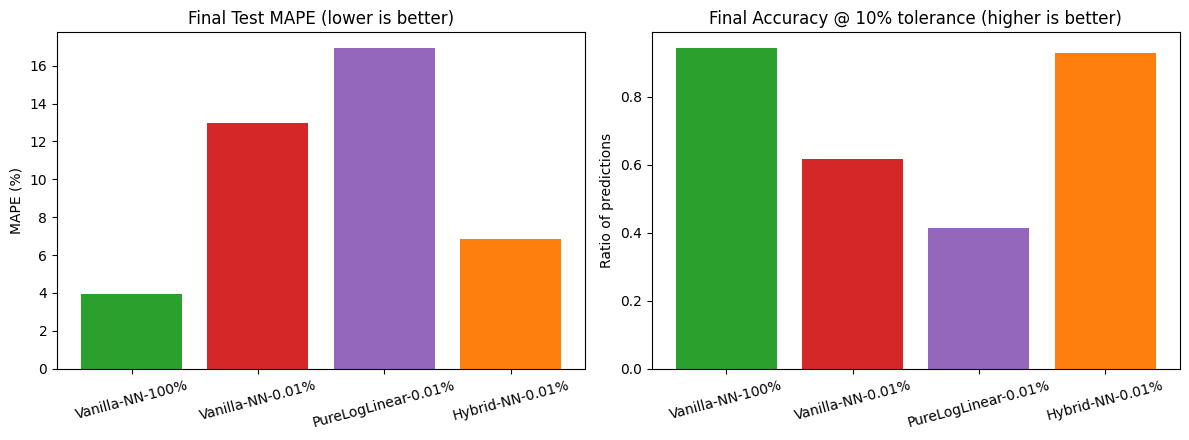

In [ ]:
summary_rows = []
for name, h in runs.items():
    if "final_test" in h:
        summary_rows.append({
            "model": name,
            "final_MAPE_%": h["final_test"]["mape"],
            "acc@10%": h["final_test"]["acc_10"],
            "acc@15%": h["final_test"]["acc_15"],
            "acc@20%": h["final_test"]["acc_20"],
        })
    else:
        summary_rows.append({
            "model": name,
            "final_MAPE_%": h["mape"][-1],
            "acc@10%": h["acc_10"][-1],
            "acc@15%": h["acc_15"][-1],
            "acc@20%": h["acc_20"][-1],
        })

print(f"{'Model':<22}{'MAPE (%)':>12}{'acc@10%':>12}{'acc@15%':>12}{'acc@20%':>12}")
for row in summary_rows:
    print(f"{row['model']:<22}{row['final_MAPE_%']:>12.2f}"
          f"{row['acc@10%']:>12.3f}{row['acc@15%']:>12.3f}{row['acc@20%']:>12.3f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
names = [r["model"] for r in summary_rows]
bar_colors = [colors[n] for n in names]

axs[0].bar(names, [r["final_MAPE_%"] for r in summary_rows], color=bar_colors)
axs[0].set_title("Final Test MAPE (lower is better)")
axs[0].set_ylabel("MAPE (%)")
axs[0].tick_params(axis="x", rotation=15)

axs[1].bar(names, [r["acc@10%"] for r in summary_rows], color=bar_colors)
axs[1].set_title("Final Accuracy @ 10% tolerance (higher is better)")
axs[1].set_ylabel("Ratio of predictions")
axs[1].tick_params(axis="x", rotation=15)

fig.tight_layout()
plt.show()
